In [1]:
!pip install gwosc

from gwosc.datasets import find_datasets
from gwosc import datasets

# 列出所有与 GWTC-5.0 相关的数据集
gwtc5_datasets = find_datasets(type='event', detector='GWTC-5.0')
print(gwtc5_datasets)

import requests
import json

# 从 GWOSC API 获取单个事件的详细参数
event_name = 'GW190521'
r = requests.get(f"https://gwosc.org/api/v2/events/{event_name}")
if r.status_code == 200:
    data = r.json()
    # 打印所有可用参数
    print(json.dumps(data, indent=2))
else:
    print("API 请求失败")

[]
{
  "name": "GW190521",
  "grace_id": "S190521g",
  "run": "O3a",
  "gcn_notice": "https://gcn.gsfc.nasa.gov/notices_l/S190521g.lvc",
  "gcn_circular": "https://gcn.nasa.gov/circulars?query=S190521g",
  "aliases": [
    "GW190521",
    "GW190521_030229"
  ],
  "versions": [
    {
      "version": 1,
      "catalog": "O3_Discovery_Papers",
      "detail_url": "https://gwosc.org/api/v2/event-versions/GW190521-v1"
    },
    {
      "version": 2,
      "catalog": "O3_Discovery_Papers",
      "detail_url": "https://gwosc.org/api/v2/event-versions/GW190521-v2"
    },
    {
      "version": 3,
      "catalog": "GWTC-2",
      "detail_url": "https://gwosc.org/api/v2/event-versions/GW190521-v3"
    },
    {
      "version": 4,
      "catalog": "GWTC-2.1-confident",
      "detail_url": "https://gwosc.org/api/v2/event-versions/GW190521-v4"
    }
  ]
}


Column names:
['name', 'shortName', 'gps', 'version', 'catalog', 'doi', 'detail_url', 'mass_1_source', 'mass_1_source_lower', 'mass_1_source_upper', 'mass_2_source', 'mass_2_source_lower', 'mass_2_source_upper', 'network_matched_filter_snr', 'network_matched_filter_snr_lower', 'network_matched_filter_snr_upper', 'luminosity_distance', 'luminosity_distance_lower', 'luminosity_distance_upper', 'chi_eff', 'chi_eff_lower', 'chi_eff_upper', 'total_mass_source', 'total_mass_source_lower', 'total_mass_source_upper', 'chirp_mass_source', 'chirp_mass_source_lower', 'chirp_mass_source_upper', 'chirp_mass', 'chirp_mass_lower', 'chirp_mass_upper', 'redshift', 'redshift_lower', 'redshift_upper', 'far', 'far_lower', 'far_upper', 'p_astro', 'p_astro_lower', 'p_astro_upper', 'final_mass_source', 'final_mass_source_lower', 'final_mass_source_upper']

Total events: 161
Mass-gap candidates: 2

Candidate list:
               name  mass_1_source  mass_2_source  redshift  \
17  GW241230_233618           68.

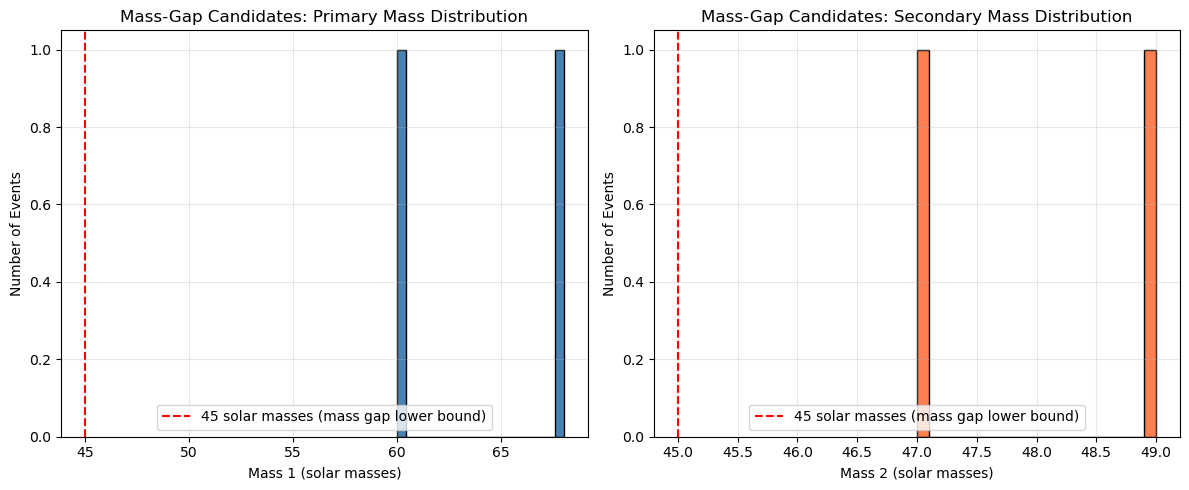

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Read the catalog
df_gw = pd.read_csv('GWTC-5.0.csv')

# 2. Check column names to find mass-related columns
print("Column names:")
print(df_gw.columns.tolist())

# 3. Select mass-gap candidates
# The columns are typically 'mass_1_source' and 'mass_2_source'
# If the column names are different, adjust them based on the output above
try:
    # Selection criteria: both masses greater than 45 solar masses
    mask = (df_gw['mass_1_source'] > 45) & (df_gw['mass_2_source'] > 45)
    gap_candidates = df_gw[mask].copy()
    
    print(f"\nTotal events: {len(df_gw)}")
    print(f"Mass-gap candidates: {len(gap_candidates)}")
    
    # 4. Display candidate information
    print("\nCandidate list:")
    print(gap_candidates[['name', 'mass_1_source', 'mass_2_source', 'redshift', 'luminosity_distance']].head(10))
    
    # 5. Plot mass distribution histograms
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    
    # Left: Distribution of mass 1
    axes[0].hist(gap_candidates['mass_1_source'], bins=20, color='steelblue', edgecolor='black')
    axes[0].axvline(45, color='red', linestyle='--', label='45 solar masses (mass gap lower bound)')
    axes[0].set_xlabel('Mass 1 (solar masses)')
    axes[0].set_ylabel('Number of Events')
    axes[0].set_title('Mass-Gap Candidates: Primary Mass Distribution')
    axes[0].legend()
    axes[0].grid(alpha=0.3)
    
    # Right: Distribution of mass 2
    axes[1].hist(gap_candidates['mass_2_source'], bins=20, color='coral', edgecolor='black')
    axes[1].axvline(45, color='red', linestyle='--', label='45 solar masses (mass gap lower bound)')
    axes[1].set_xlabel('Mass 2 (solar masses)')
    axes[1].set_ylabel('Number of Events')
    axes[1].set_title('Mass-Gap Candidates: Secondary Mass Distribution')
    axes[1].legend()
    axes[1].grid(alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('mass_gap_candidates.png', dpi=150)
    plt.show()
    
except KeyError as e:
    print(f"Column not found: {e}")
    print("Please check the column names and adjust the code accordingly.")

=== Required Lensing Magnification ===

GW241230_233618:
  Mass 1: 68.0 solar masses → requires mass magnification 1.51x
         → requires lensing magnification 2.28x
  Mass 2: 49.0 solar masses → requires mass magnification 1.09x
         → requires lensing magnification 1.19x

GW241125_010116:
  Mass 1: 60.0 solar masses → requires mass magnification 1.33x
         → requires lensing magnification 1.78x
  Mass 2: 47.0 solar masses → requires mass magnification 1.04x
         → requires lensing magnification 1.09x


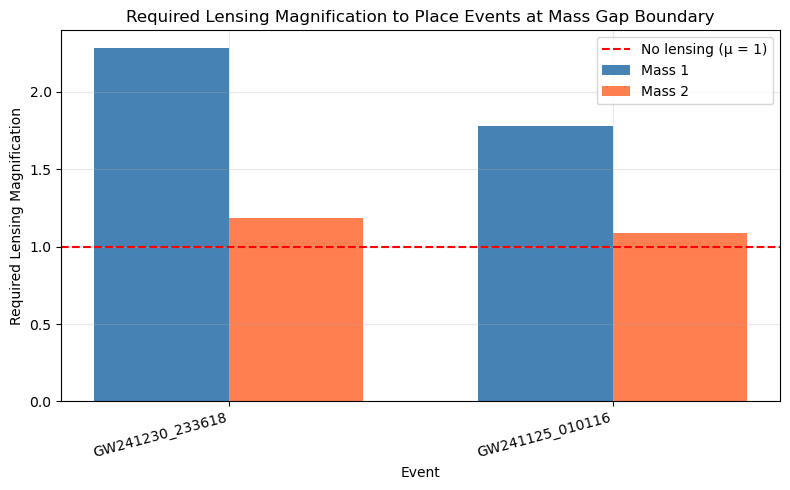

In [4]:
# Calculate and visualize the required lensing magnification
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use the candidate list we already have
# gap_candidates contains the two events
gap_candidates = df_gw[mask].copy()

# Assume the true mass is at the mass gap boundary (45 solar masses)
true_mass_assumption = 45.0

# Calculate required mass magnification and lensing magnification for each event
results = []
for idx, row in gap_candidates.iterrows():
    m1 = row['mass_1_source']
    m2 = row['mass_2_source']
    
    mass_mag_1 = m1 / true_mass_assumption
    mass_mag_2 = m2 / true_mass_assumption
    
    lens_mag_1 = mass_mag_1**2
    lens_mag_2 = mass_mag_2**2
    
    results.append({
        'name': row['name'],
        'mass_1': m1,
        'mass_2': m2,
        'mass_mag_1': mass_mag_1,
        'mass_mag_2': mass_mag_2,
        'lens_mag_1': lens_mag_1,
        'lens_mag_2': lens_mag_2
    })

results_df = pd.DataFrame(results)

print("=== Required Lensing Magnification ===")
for _, row in results_df.iterrows():
    print(f"\n{row['name']}:")
    print(f"  Mass 1: {row['mass_1']} solar masses → requires mass magnification {row['mass_mag_1']:.2f}x")
    print(f"         → requires lensing magnification {row['lens_mag_1']:.2f}x")
    print(f"  Mass 2: {row['mass_2']} solar masses → requires mass magnification {row['mass_mag_2']:.2f}x")
    print(f"         → requires lensing magnification {row['lens_mag_2']:.2f}x")

# Plot the required lensing magnification
fig, ax = plt.subplots(figsize=(8, 5))

x = np.arange(len(results_df))
width = 0.35

ax.bar(x - width/2, results_df['lens_mag_1'], width, label='Mass 1', color='steelblue')
ax.bar(x + width/2, results_df['lens_mag_2'], width, label='Mass 2', color='coral')

ax.set_xlabel('Event')
ax.set_ylabel('Required Lensing Magnification')
ax.set_title('Required Lensing Magnification to Place Events at Mass Gap Boundary')
ax.set_xticks(x)
ax.set_xticklabels(results_df['name'], rotation=15, ha='right')
ax.axhline(1, color='red', linestyle='--', label='No lensing (μ = 1)')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('required_lensing_magnification.png', dpi=150)
plt.show()